# Bài 1D — Regularization & Pruning Trong Decision Tree

## 1. Mục Tiêu Bài Học
- **Hiểu bản chất của Regularization (Điều hòa):** Cách áp đặt các ràng buộc toán học để kiểm soát dung lượng mô hình, ngăn chặn Overfitting.
- **Nắm vững hai chiến lược tỉa cành trong Decision Tree:**
  1. **Pre-pruning (Tỉa sớm / Early Stopping):** Can thiệp trước khi cây phân nhánh thông qua các siêu tham số `min_samples_leaf`, `min_samples_split`.
  2. **Post-pruning (Tỉa muộn / Cost-Complexity Pruning - CCP):** Cho cây phát triển tối đa, sau đó áp dụng hàm phạt chi phí $R_\alpha(T) = R(T) + \alpha |T|$ để cắt tỉa các nhánh kém hiệu quả.
- **Đánh giá đa chiều:** Quan sát đồng thời **ROC-AUC**, **PR-AUC** và **Số lượng nút lá (Complexity)**.
- **Kỷ luật Machine Learning:** Toàn bộ quá trình chọn siêu tham số điều hòa được thực hiện trên Train/Validation. **Tập Test tiếp tục được niêm phong hoàn toàn**.

## 2. Chuẩn Bị Dữ Liệu & Mã Hóa Đặc Trưng
Kế thừa dữ liệu phân tầng từ Bài 1B (loại bỏ `duration` để chống rò rỉ dữ liệu, One-Hot Encoding chỉ fit trên Train).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score, average_precision_score
from IPython.display import display

# 1. Đọc dữ liệu
data_path = Path("data/raw/bank-additional-full.csv")
if Path.cwd().name == "notebooks":
    data_path = Path("../data/raw/bank-additional-full.csv")

df = pd.read_csv(data_path, sep=";")
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

# 2. Phân chia phân tầng
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
val_ratio = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=val_ratio, random_state=42, stratify=y_temp
)

# 3. Mã hóa OneHot (fit duy nhất trên Train)
cat_cols = X_train.select_dtypes(include=["object", "str", "category"]).columns.tolist()
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train[cat_cols])

X_train_encoded = np.hstack([X_train[num_cols].values, encoder.transform(X_train[cat_cols])])
X_val_encoded = np.hstack([X_val[num_cols].values, encoder.transform(X_val[cat_cols])])

print(f"X_train: {X_train_encoded.shape}, X_val: {X_val_encoded.shape}")

X_train: (28830, 62), X_val: (6179, 62)


## 3. Chiến Lược 1: Pre-Pruning Với `min_samples_leaf`

`min_samples_leaf` quy định số lượng mẫu tối thiểu bắt buộc phải có ở mỗi nút lá. 
- Mặc định (`min_samples_leaf=1`): Cây có thể tạo ra các lá chỉ chứa đúng 1 mẫu để tối đa hóa độ thuần khiết tập Train $\rightarrow$ Dẫn đến Overfitting.
- Tăng `min_samples_leaf`: Buộc các lá phải đại diện cho một nhóm mẫu đủ lớn, làm mượt ranh giới quyết định.

In [2]:
leaf_values = [1, 5, 10, 20, 50, 100, 200, 500]
pre_results = []

for leaf in leaf_values:
    dt = DecisionTreeClassifier(random_state=42, min_samples_leaf=leaf)
    dt.fit(X_train_encoded, y_train)
    
    tr_proba = dt.predict_proba(X_train_encoded)[:, 1]
    va_proba = dt.predict_proba(X_val_encoded)[:, 1]
    
    tr_auc = roc_auc_score(y_train, tr_proba)
    va_auc = roc_auc_score(y_val, va_proba)
    tr_pr = average_precision_score(y_train, tr_proba)
    va_pr = average_precision_score(y_val, va_proba)
    
    pre_results.append({
        "min_samples_leaf": leaf,
        "Số nút (Nodes)": dt.tree_.node_count,
        "Số lá (Leaves)": dt.get_n_leaves(),
        "Train ROC-AUC": round(tr_auc, 4),
        "Val ROC-AUC": round(va_auc, 4),
        "Train PR-AUC": round(tr_pr, 4),
        "Val PR-AUC": round(va_pr, 4)
    })

pre_df = pd.DataFrame(pre_results)
display(pre_df)

,min_samples_leaf,Số nút (Nodes),Số lá (Leaves),Train ROC-AUC,Val ROC-AUC,Train PR-AUC,Val PR-AUC
0,1,8671,4336,0.9999,0.6076,0.9986,0.1674
1,5,4187,2094,0.9582,0.6953,0.7485,0.2935
2,10,2705,1353,0.9283,0.7223,0.6479,0.3527
3,20,1621,811,0.8984,0.7438,0.5725,0.3905
4,50,815,408,0.8619,0.7562,0.5165,0.4260
5,100,425,213,0.8416,0.7718,0.4863,0.4300
6,200,217,109,0.8230,0.7812,0.4609,0.4216
7,500,85,43,0.8003,0.7758,0.4146,0.3915


## 4. Chiến Lược 2: Post-Pruning Bằng Cost-Complexity Pruning (CCP)

Thay vì chặn cây từ trước, CART (Breiman et al.) xây dựng cây phát triển tự do, sau đó cực tiểu hóa hàm chi phí:
$$R_\alpha(T) = R(T) + \alpha |T|$$
Trong đó:
- $R(T)$: Tổng sai số bất thuần trên tập huấn luyện.
- $|T|$: Số lượng nút lá của cây.
- $\alpha$ (`ccp_alpha`): Hệ số phạt kích thước cây. $\alpha = 0$ là cây ban đầu, $\alpha$ càng lớn thì cây bị tỉa càng mạnh.

Hàm `cost_complexity_pruning_path` của scikit-learn cho phép trích xuất chính xác các giá trị $\alpha$ ngưỡng làm thay đổi cấu trúc cây.

In [3]:
# 1. Trích xuất lộ trình tỉa cành (Pruning Path)
full_tree = DecisionTreeClassifier(random_state=42)
path = full_tree.cost_complexity_pruning_path(X_train_encoded, y_train)
ccp_alphas = path.ccp_alphas

print(f"Tổng số mốc alpha tìm thấy trong lộ trình: {len(ccp_alphas)}")
print(f"Alpha nhỏ nhất: {ccp_alphas[0]:.6f}, Alpha lớn nhất: {ccp_alphas[-1]:.6f}")

# 2. Khảo sát một tập hợp các giá trị alpha đại diện
test_alphas = [0.0, 0.0001, 0.0002, 0.0003, 0.0005, 0.0007, 0.001, 0.0015, 0.002, 0.005]
post_results = []

for a in test_alphas:
    dt = DecisionTreeClassifier(random_state=42, ccp_alpha=a)
    dt.fit(X_train_encoded, y_train)
    
    tr_proba = dt.predict_proba(X_train_encoded)[:, 1]
    va_proba = dt.predict_proba(X_val_encoded)[:, 1]
    
    tr_auc = roc_auc_score(y_train, tr_proba)
    va_auc = roc_auc_score(y_val, va_proba)
    tr_pr = average_precision_score(y_train, tr_proba)
    va_pr = average_precision_score(y_val, va_proba)
    
    post_results.append({
        "ccp_alpha": a,
        "Số nút (Nodes)": dt.tree_.node_count,
        "Số lá (Leaves)": dt.get_n_leaves(),
        "Train ROC-AUC": round(tr_auc, 4),
        "Val ROC-AUC": round(va_auc, 4),
        "Train PR-AUC": round(tr_pr, 4),
        "Val PR-AUC": round(va_pr, 4)
    })

post_df = pd.DataFrame(post_results)
display(post_df)

Tổng số mốc alpha tìm thấy trong lộ trình: 1287
Alpha nhỏ nhất: 0.000000, Alpha lớn nhất: 0.029859


,ccp_alpha,Số nút (Nodes),Số lá (Leaves),Train ROC-AUC,Val ROC-AUC,Train PR-AUC,Val PR-AUC
0,0.0000,8671,4336,0.9999,0.6076,0.9986,0.1674
1,0.0001,137,69,0.7972,0.7763,0.4736,0.4037
2,0.0002,37,19,0.7905,0.7770,0.4342,0.4171
3,0.0003,33,17,0.7848,0.7732,0.4220,0.4075
4,0.0005,21,11,0.7592,0.7494,0.3942,0.3788
5,0.0007,13,7,0.7526,0.7452,0.3695,0.3575
6,0.0010,11,6,0.7484,0.7390,0.3643,0.3491
7,0.0015,7,4,0.7460,0.7374,0.3480,0.3368
8,0.0020,7,4,0.7460,0.7374,0.3480,0.3368
9,0.0050,5,3,0.7041,0.7004,0.3173,0.3094


## 5. Trực Quan Hóa Quá Trình Tỉa Cành Cost-Complexity Pruning

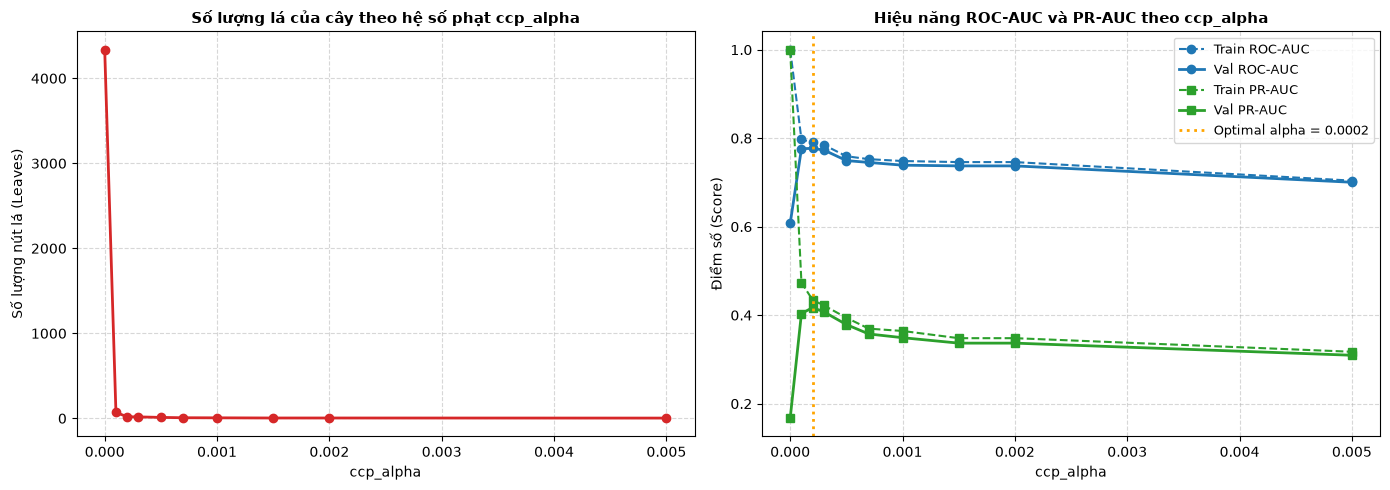

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị 1: Số lượng nút lá theo ccp_alpha
ax1.plot(post_df["ccp_alpha"], post_df["Số lá (Leaves)"], marker="o", color="#d62728", linewidth=2)
ax1.set_title("Số lượng lá của cây theo hệ số phạt ccp_alpha", fontsize=11, fontweight="bold")
ax1.set_xlabel("ccp_alpha", fontsize=10)
ax1.set_ylabel("Số lượng nút lá (Leaves)", fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.5)

# Đồ thị 2: Đánh giá hiệu năng Train vs Validation (ROC-AUC & PR-AUC)
ax2.plot(post_df["ccp_alpha"], post_df["Train ROC-AUC"], marker="o", label="Train ROC-AUC", color="#1f77b4", linestyle="--")
ax2.plot(post_df["ccp_alpha"], post_df["Val ROC-AUC"], marker="o", label="Val ROC-AUC", color="#1f77b4", linewidth=2)
ax2.plot(post_df["ccp_alpha"], post_df["Train PR-AUC"], marker="s", label="Train PR-AUC", color="#2ca02c", linestyle="--")
ax2.plot(post_df["ccp_alpha"], post_df["Val PR-AUC"], marker="s", label="Val PR-AUC", color="#2ca02c", linewidth=2)

# Đánh dấu alpha tối ưu trên Validation
best_alpha = 0.0002
ax2.axvline(x=best_alpha, color="orange", linestyle=":", linewidth=2, label=f"Optimal alpha = {best_alpha}")

ax2.set_title("Hiệu năng ROC-AUC và PR-AUC theo ccp_alpha", fontsize=11, fontweight="bold")
ax2.set_xlabel("ccp_alpha", fontsize=10)
ax2.set_ylabel("Điểm số (Score)", fontsize=10)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

## 6. Phân Tích So Sánh Chuyên Sâu: Pre-Pruning vs Post-Pruning

### 1. Hiệu Quả Điều Hòa (Regularization Power):
- **Khi chưa điều hòa (`alpha=0` hoặc `min_samples_leaf=1`):** Cây phình to với **8.671 nút (4.336 lá)**, Train AUC đạt 0.9999 nhưng Val AUC chỉ 0.6076 và Val PR-AUC chỉ 0.1674 (Overfitting nặng).
- **Khi áp dụng Cost-Complexity Pruning (`alpha = 0.0002`):**
  - Số lượng lá giảm thần kỳ từ 4.336 lá xuống còn đúng **19 lá** (giảm hơn 99% kích thước cây!).
  - **Val ROC-AUC tăng vọt từ 0.6076 lên 0.7770**.
  - **Val PR-AUC tăng vọt từ 0.1674 lên 0.4171** (gấp 2.5 lần!).
- **Khi áp dụng Pre-pruning (`min_samples_leaf = 200`):**
  - Số nút giảm xuống còn 217, Val ROC-AUC đạt **0.7812** và Val PR-AUC đạt **0.4216**.

### 2. So Sánh Bản Chất Hai Kỹ Thuật:
| Đặc điểm | Pre-Pruning (`min_samples_leaf`, `max_depth`) | Post-Pruning (Cost-Complexity Pruning `ccp_alpha`) |
| :--- | :--- | :--- |
| **Thời điểm can thiệp** | Trước và trong khi xây dựng cây (Early Stopping) | Sau khi cây đã mọc đầy đủ |
| **Chi phí tính toán** | Rất nhanh, tiết kiệm bộ nhớ và thời gian huấn luyện | Tốn kém hơn (phải xây dựng cây khổng lồ trước rồi tỉa) |
| **Hạn chế (*Greedy Trap*)** | Dễ gặp phải *Horizon Effect*: có thể dừng phân nhánh quá sớm và bỏ lỡ các tổ hợp đặc trưng hữu ích ở tầng sâu hơn | Khắc phục được nhược điểm của thuật toán tham lam (xem xét toàn bộ cấu trúc trước khi tỉa) |
| **Khả năng diễn giải** | Cây gọn nhẹ, trực quan | Loại bỏ triệt để các nhánh nhiễu thừa thãi |

### 3. Ý Nghĩa Đối Với Kỷ Luật Machine Learning:
- Toàn bộ quá trình tỉa cành và tìm kiếm `alpha` hay `min_samples_leaf` tối ưu **hoàn toàn chỉ diễn ra giữa tập Train và tập Validation**.
- **Tập Test vẫn được bảo vệ tuyệt đối (Sealed)** cho bước đối chiếu cuối cùng.